# DATA ANALYTICS ML CHALLENGE / 2026-2
## Laboratorio 2. PCA y evaluación de mejoras al modelo (Semana 14)

Profesor: Elias Buitrago Bolivar  
Universidad Central  
Caso: Brazilian E-Commerce Public Dataset by Olist

Objetivo: examinar si reducir variables con PCA y cambiar la regularización permite identificar mejor los pedidos que llegarían tarde, comparando los modelos con métricas, costo empresarial y una prueba estadística.



## 1. Carga de datos



In [6]:
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             confusion_matrix, mean_absolute_error)
from sklearn.base import clone
from sklearn.decomposition import PCA
from scipy.stats import ks_2samp
import matplotlib.pyplot as plt


In [7]:
ORIGEN = ('https://raw.githubusercontent.com/spdrio/'
          'Brazilian-E-Commerce-Public-Dataset-by-Olist/'
          'fa0cc6d1aff713d3c8b9a1e633b56889881848bf/files')

pedidos = pd.read_csv(f'{ORIGEN}/olist_orders_dataset.csv')
items = pd.read_csv(f'{ORIGEN}/olist_order_items_dataset.csv')
productos = pd.read_csv(f'{ORIGEN}/olist_products_dataset.csv')
clientes = pd.read_csv(f'{ORIGEN}/olist_customers_dataset.csv')
vendedores = pd.read_csv(f'{ORIGEN}/olist_sellers_dataset.csv')
pagos = pd.read_csv(f'{ORIGEN}/olist_order_payments_dataset.csv')
categorias = pd.read_csv(f'{ORIGEN}/product_category_name_translation.csv')

print('Pedidos:', pedidos.shape)
print('Items:', items.shape)
print('Productos:', productos.shape)
print('Clientes:', clientes.shape)
print('Vendedores:', vendedores.shape)
print('Pagos:', pagos.shape)

Pedidos: (99441, 8)
Items: (112650, 7)
Productos: (32951, 9)
Clientes: (99441, 5)
Vendedores: (3095, 4)
Pagos: (103886, 5)


## 2. Preparación de variables



In [8]:
# Información de los productos y vendedores incluidos en cada pedido.
items = items.merge(productos, on='product_id', how='left', validate='many_to_one')
items = items.merge(vendedores, on='seller_id', how='left', validate='many_to_one')
items = items.merge(categorias, on='product_category_name',
                    how='left', validate='many_to_one')

items['volumen_cm3'] = (items['product_length_cm'] * items['product_height_cm']
                       * items['product_width_cm'])
items['categoria'] = items['product_category_name_english'].fillna(
    items['product_category_name']).fillna('sin_categoria')

# Resumen de productos: una fila por pedido.
resumen_items = items.groupby('order_id', as_index=False).agg(
    valor_productos=('price', 'sum'),
    valor_flete=('freight_value', 'sum'),
    precio_maximo=('price', 'max'),
    cantidad_items=('order_item_id', 'count'),
    cantidad_productos=('product_id', 'nunique'),
    cantidad_vendedores=('seller_id', 'nunique'),
    peso_total_g=('product_weight_g', 'sum'),
    peso_maximo_g=('product_weight_g', 'max'),
    volumen_total_cm3=('volumen_cm3', 'sum'),
    fotos_promedio=('product_photos_qty', 'mean'),
    descripcion_promedio=('product_description_lenght', 'mean'),
    nombre_promedio=('product_name_lenght', 'mean'),
)

# Categoría y vendedor del producto de mayor precio del pedido.
principal = (items.sort_values(['order_id', 'price', 'order_item_id'],
                                ascending=[True, False, True])
             .drop_duplicates('order_id'))
principal = principal[['order_id', 'categoria', 'seller_state', 'seller_city']]
principal = principal.rename(columns={
    'categoria': 'categoria_principal',
    'seller_state': 'estado_vendedor',
    'seller_city': 'ciudad_vendedor'
})

In [9]:
# Los pagos también pueden aparecer en varias filas por pedido.
resumen_pagos = pagos.groupby('order_id', as_index=False).agg(
    numero_pagos=('payment_sequential', 'count'),
    cuotas_maximas=('payment_installments', 'max'),
    valor_pagado=('payment_value', 'sum'),
)

pago_principal = (pagos.sort_values(['order_id', 'payment_value'],
                                    ascending=[True, False])
                  .drop_duplicates('order_id'))
pago_principal = pago_principal[['order_id', 'payment_type']].rename(
    columns={'payment_type': 'tipo_pago_principal'})

# Integración de las tablas: una fila por pedido.
data = pedidos.merge(clientes[['customer_id', 'customer_state', 'customer_city']],
                     on='customer_id', how='inner', validate='one_to_one')
data = data.merge(resumen_items, on='order_id', how='inner', validate='one_to_one')
data = data.merge(principal, on='order_id', how='left', validate='one_to_one')
data = data.merge(resumen_pagos, on='order_id', how='left', validate='one_to_one')
data = data.merge(pago_principal, on='order_id', how='left', validate='one_to_one')

assert data['order_id'].is_unique, 'Hay pedidos duplicados después de las uniones.'
print('Pedidos integrados:', len(data))

Pedidos integrados: 98666


In [10]:
# Se consideran pedidos entregados con fechas completas y coherentes.
fechas = ['order_purchase_timestamp', 'order_estimated_delivery_date',
          'order_delivered_customer_date']
for columna in fechas:
    data[columna] = pd.to_datetime(data[columna], errors='coerce')

data = data.loc[data['order_status'] == 'delivered'].dropna(subset=fechas).copy()
compra = data['order_purchase_timestamp'].dt.normalize()
prevista = data['order_estimated_delivery_date'].dt.normalize()
real = data['order_delivered_customer_date'].dt.normalize()

data['dias_prometidos'] = (prevista - compra).dt.days
data['dias_entrega'] = (real - compra).dt.days
data['is_late'] = (real > prevista).astype(int)
data['mes_compra'] = compra.dt.month
data['dia_semana_compra'] = compra.dt.dayofweek
data['dia_mes_compra'] = compra.dt.day
data['hora_compra'] = data['order_purchase_timestamp'].dt.hour
data['compra_fin_semana'] = (data['dia_semana_compra'] >= 5).astype(int)

data['vendedor_mismo_estado'] = (
    data['customer_state'] == data['estado_vendedor']).astype(int)
data['vendedor_misma_ciudad'] = (
    data['vendedor_mismo_estado'].eq(1) &
    data['customer_city'].str.lower().eq(data['ciudad_vendedor'].str.lower())
).astype(int)
data['proporcion_flete'] = data['valor_flete'] / (
    data['valor_productos'] + data['valor_flete']).replace(0, np.nan)

data = data.loc[(data['dias_prometidos'] >= 0) &
                (data['dias_entrega'] >= 0)].copy()
data = data.sort_values('order_id').reset_index(drop=True)

print('Pedidos disponibles:', len(data))
print('Entregas tardías:', round(100 * data['is_late'].mean(), 2), '%')

Pedidos disponibles: 96470
Entregas tardías: 6.77 %


### Variables del modelo



In [11]:
columnas_numericas = [
    'dias_prometidos', 'mes_compra', 'dia_semana_compra',
    'dia_mes_compra', 'hora_compra', 'compra_fin_semana',
    'valor_productos', 'valor_flete', 'precio_maximo',
    'cantidad_items', 'cantidad_productos', 'cantidad_vendedores',
    'peso_total_g', 'peso_maximo_g', 'volumen_total_cm3',
    'fotos_promedio', 'descripcion_promedio', 'nombre_promedio',
    'numero_pagos', 'cuotas_maximas', 'valor_pagado',
    'vendedor_mismo_estado', 'vendedor_misma_ciudad', 'proporcion_flete'
]
columnas_categoricas = [
    'customer_state', 'estado_vendedor',
    'categoria_principal', 'tipo_pago_principal'
]
columnas = columnas_numericas + columnas_categoricas

assert data['order_id'].is_unique
assert len(data) >= 35000
print('Variables predictoras:', len(columnas))
print('Numéricas:', len(columnas_numericas), '| Categóricas:', len(columnas_categoricas))

Variables predictoras: 28
Numéricas: 24 | Categóricas: 4


### Muestra individual


In [12]:
# Escriba el ID que le asignó el profesor (01 se escribe 1).
ID_ESTUDIANTE = 9
assert isinstance(ID_ESTUDIANTE, int) and 1 <= ID_ESTUDIANTE <= 30, (
    'El ID debe ser un número entero entre 1 y 30.')

semilla = 1000 + ID_ESTUDIANTE
identificador = f'{ID_ESTUDIANTE:02d}'

muestra, _ = train_test_split(data, train_size=35000,
                             random_state=semilla, stratify=data['is_late'])
muestra = muestra.sort_values('order_id').reset_index(drop=True)

train, temporal = train_test_split(muestra, test_size=0.30,
                                  random_state=semilla, stratify=muestra['is_late'])
valid, test = train_test_split(temporal, test_size=0.50,
                               random_state=semilla, stratify=temporal['is_late'])

X_train, y_train = train[columnas], train['is_late']
X_valid, y_valid = valid[columnas], valid['is_late']

huella_muestra = hashlib.sha256('|'.join(muestra['order_id']).encode()).hexdigest()[:12]
print('Estudiante ID:', identificador, '| Semilla:', semilla)
print('Muestra:', len(muestra), '| Train:', len(train),
      '| Valid:', len(valid), '| Test:', len(test))
print('Huella de muestra:', huella_muestra)

Estudiante ID: 09 | Semilla: 1009
Muestra: 35000 | Train: 24500 | Valid: 5250 | Test: 5250
Huella de muestra: 177ef3fcd2da


## 3. PCA y reducción de dimensionalidad

Antes de aplicar PCA, las variables numéricas se imputan (mediana) y se estandarizan. Estas transformaciones se ajustan únicamente con los datos de entrenamiento.

### Actividad 1. Varianza explicada acumulada

Generar la curva de varianza acumulada, registrar cuántas variables numéricas había y cuántas componentes explican al menos el 90 %.

Variables numéricas originales: 24
Componentes para >= 90% de varianza: 15
Varianza acumulada con esas componentes: 0.9079
Varianza de CP1: 0.195


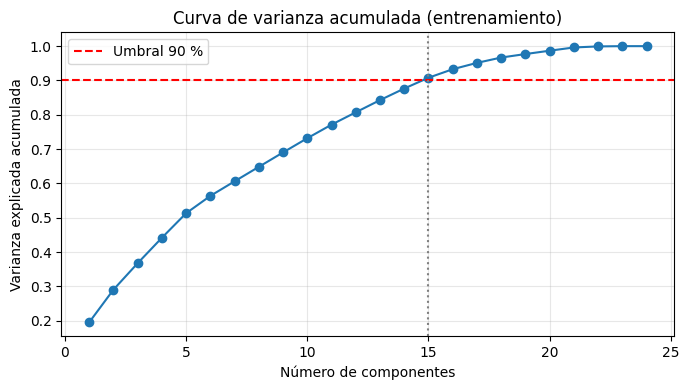


Mayores pesos absolutos en CP1:
valor_pagado       0.402
valor_productos    0.387
precio_maximo      0.355
peso_total_g       0.350
valor_flete        0.338
Name: CP1, dtype: float64


In [13]:
prep_num = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
Z_train = prep_num.fit_transform(X_train[columnas_numericas])

pca_full = PCA(svd_solver='full', random_state=semilla).fit(Z_train)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
n_componentes = int(np.argmax(var_acum >= 0.90) + 1)

print('Variables numéricas originales:', len(columnas_numericas))
print('Componentes para >= 90% de varianza:', n_componentes)
print('Varianza acumulada con esas componentes:', round(var_acum[n_componentes - 1], 4))
print('Varianza de CP1:', round(pca_full.explained_variance_ratio_[0], 4))

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(var_acum) + 1), var_acum, marker='o')
plt.axhline(0.90, color='red', linestyle='--', label='Umbral 90 %')
plt.axvline(n_componentes, color='gray', linestyle=':')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('Curva de varianza acumulada (entrenamiento)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

pesos = pd.DataFrame(pca_full.components_[:2].T, index=columnas_numericas, columns=['CP1', 'CP2'])
print('\nMayores pesos absolutos en CP1:')
print(pesos['CP1'].abs().sort_values(ascending=False).head(5).round(3))

## 4. Comparación de modelos

Los cuatro modelos usan la misma muestra, la misma partición, `class_weight='balanced'` y el umbral 0,50. Solo cambian la reducción de dimensionalidad (con o sin PCA) y el valor de `C`.

### Actividad 2. Comparación de las cuatro configuraciones

Comparación del Accuracy, Precision, Recall, F1 y Average Precision (AP) de los experimentos A, B, C y D en validación.

In [14]:
def construir_modelo(usar_pca, C):
    pasos_num = [SimpleImputer(strategy='median'), StandardScaler()]
    if usar_pca:
        pasos_num.append(PCA(n_components=0.90, svd_solver='full', random_state=semilla))
    prep = ColumnTransformer([
        ('numericas', make_pipeline(*pasos_num), columnas_numericas),
        ('categoricas', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                     OneHotEncoder(handle_unknown='ignore')),
         columnas_categoricas)
    ])
    clf = LogisticRegression(C=C, class_weight='balanced', max_iter=1000,
                             random_state=semilla)
    return make_pipeline(prep, clf)

experimentos = {
    'A. Sin PCA, C=1.0':   (False, 1.0),
    'B. PCA 90%, C=1.0':   (True, 1.0),
    'C. PCA 90%, C=0.1':   (True, 0.1),
    'D. PCA 90%, C=10.0':  (True, 10.0),
}

filas, modelos = [], {}
for nombre, (usar_pca, C) in experimentos.items():
    m = construir_modelo(usar_pca, C)
    m.fit(X_train, y_train)
    p = m.predict(X_valid)
    pr = m.predict_proba(X_valid)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_valid, p).ravel()
    filas.append({
        'experimento': nombre,
        'accuracy': accuracy_score(y_valid, p),
        'precision': precision_score(y_valid, p, zero_division=0),
        'recall': recall_score(y_valid, p, zero_division=0),
        'f1': f1_score(y_valid, p, zero_division=0),
        'ap': average_precision_score(y_valid, pr),
        'roc_auc': roc_auc_score(y_valid, pr),
        'VP': tp, 'FP': fp, 'FN': fn, 'VN': tn,
        'costo_R$': 8 * fp + 35 * fn,
    })
    modelos[nombre] = m

resultados = pd.DataFrame(filas).set_index('experimento')
print('Componentes retenidas en B/C/D:',
      modelos['B. PCA 90%, C=1.0'].named_steps['columntransformer']
      .named_transformers_['numericas'].named_steps['pca'].n_components_)
resultados.round(3)

Componentes retenidas en B/C/D: 15


,accuracy,precision,recall,f1,ap,roc_auc,VP,FP,FN,VN,costo_R$
experimento,,,,,,,,,,,
"A. Sin PCA, C=1.0",0.664,0.126,0.668,0.212,0.165,0.715,237,1646,118,3249,17298
"B. PCA 90%, C=1.0",0.634,0.111,0.631,0.189,0.138,0.674,224,1788,131,3107,18889
"C. PCA 90%, C=0.1",0.636,0.113,0.637,0.191,0.135,0.676,226,1782,129,3113,18771
"D. PCA 90%, C=10.0",0.635,0.111,0.631,0.190,0.137,0.673,224,1785,131,3110,18865


### Actividad 3. Costo empresarial

Con el supuesto de R\$ 8 por falso positivo y R\$ 35 por falso negativo, calcular los errores y el costo total de cada configuración, y elijir un modelo.

In [15]:
ref = resultados[['VP', 'FP', 'FN', 'VN', 'costo_R$']].copy()
ref['costo_FP_R$'] = 8 * ref['FP']
ref['costo_FN_R$'] = 35 * ref['FN']
print(ref[['FP', 'FN', 'costo_FP_R$', 'costo_FN_R$', 'costo_R$']])

mejor_costo = resultados['costo_R$'].idxmin()
mejor_f1 = resultados['f1'].idxmax()
mejor_recall = resultados['recall'].idxmax()
mejor_acc = resultados['accuracy'].idxmax()
print('\nMenor costo :', mejor_costo, '| R$', int(resultados.loc[mejor_costo, 'costo_R$']))
print('Mejor F1    :', mejor_f1)
print('Mejor Recall:', mejor_recall)
print('Mejor Accuracy:', mejor_acc)

                      FP   FN  costo_FP_R$  costo_FN_R$  costo_R$
experimento                                                      
A. Sin PCA, C=1.0   1646  118        13168         4130     17298
B. PCA 90%, C=1.0   1788  131        14304         4585     18889
C. PCA 90%, C=0.1   1782  129        14256         4515     18771
D. PCA 90%, C=10.0  1785  131        14280         4585     18865

Menor costo : A. Sin PCA, C=1.0 | R$ 17298
Mejor F1    : A. Sin PCA, C=1.0
Mejor Recall: A. Sin PCA, C=1.0
Mejor Accuracy: A. Sin PCA, C=1.0


## 5. Validación estadística

### Actividad 4. Prueba de Kolmogorov-Smirnov sobre `valor_flete`

- H0: `valor_flete` tiene la misma distribución en entrenamiento y validación.
- H1: las distribuciones son diferentes.
- Nivel de significancia: α = 0,05.

n entrenamiento: 24500 | n validación: 5250
Estadístico D: 0.0104
Valor p: 0.7343
Decisión (alpha = 0.05): No rechazar H0
Empates: valores únicos de flete en train = 4646 de 24500

Descriptivas:
          train    valid
count  24500.00  5250.00
mean      22.82    23.06
std       20.63    20.83
min        0.00     0.00
25%       13.92    13.92
50%       17.19    17.14
75%       24.13    24.94
max      502.98   325.04


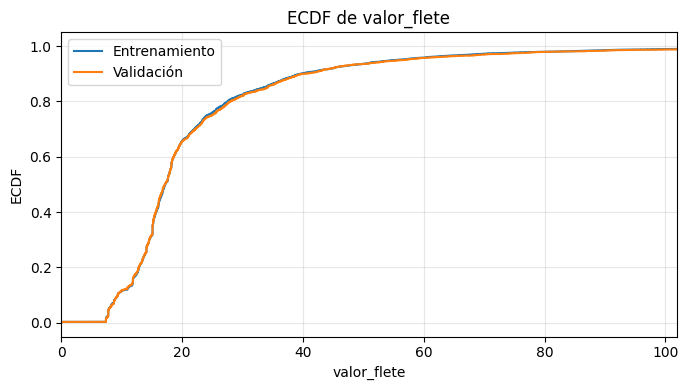

In [16]:
a = train['valor_flete'].dropna()
b = valid['valor_flete'].dropna()
ks = ks_2samp(a, b, alternative='two-sided')
alpha = 0.05
decision = 'Rechazar H0' if ks.pvalue < alpha else 'No rechazar H0'

print('n entrenamiento:', len(a), '| n validación:', len(b))
print('Estadístico D:', round(ks.statistic, 4))
print('Valor p:', round(ks.pvalue, 4))
print('Decisión (alpha = 0.05):', decision)
print('Empates: valores únicos de flete en train =', a.nunique(), 'de', len(a))
print('\nDescriptivas:')
print(pd.DataFrame({'train': a.describe(), 'valid': b.describe()}).round(2))

xs = np.sort(a.values); xv = np.sort(b.values)
plt.figure(figsize=(7, 4))
plt.step(xs, np.arange(1, len(xs) + 1) / len(xs), label='Entrenamiento')
plt.step(xv, np.arange(1, len(xv) + 1) / len(xv), label='Validación')
plt.xlim(0, np.percentile(xs, 99))
plt.xlabel('valor_flete'); plt.ylabel('ECDF'); plt.legend(); plt.grid(alpha=0.3)
plt.title('ECDF de valor_flete'); plt.tight_layout(); plt.show()

### Autoverificación

Ejecute estas comprobaciones después de completar las actividades.

In [17]:
assert len(muestra) == 35000
assert (len(train), len(valid), len(test)) == (24500, 5250, 5250)
assert set(train['order_id']).isdisjoint(valid['order_id'])
assert set(train['order_id']).isdisjoint(test['order_id'])
assert set(valid['order_id']).isdisjoint(test['order_id'])
assert 1 <= n_componentes <= len(columnas_numericas)
assert var_acum[n_componentes - 1] >= 0.90
assert resultados.shape[0] == 4
assert (resultados['FP'] + resultados['FN'] + resultados['VP'] + resultados['VN'] == len(valid)).all()
assert np.allclose(resultados['costo_R$'], 8 * resultados['FP'] + 35 * resultados['FN'])
assert 0 <= ks.statistic <= 1 and 0 <= ks.pvalue <= 1
print('Autoverificación superada.')

Autoverificación superada.


## 6. Interpretación de negocio

**1. PCA y reducción de dimensionalidad** (cuántas variables numéricas, cuántas componentes, qué información podría perderse):

Respuesta:

Se enía 24 variables numéricas y se necesito 15 componentes para explicar al menos el 90% de la varianza (quedó en 90.8%). Eso es una reducción modesta: Se logro bajar de 24 a 15, y la primera componente explica solo 19.5%, así que la información está repartida y no hay una dirección que domine. En CP1 pesan sobre todo valor_pagado, valor_productos y precio_maximo, que son variables de dinero que se mueven juntas. Al comprimir se puede perder información útil para distinguir los pedidos tardíos, porque PCA conserva varianza, no capacidad de predicción.

**2. Comparación de modelos** (sin PCA frente a con PCA; efecto de C; Accuracy, Precision, Recall, F1 y AP):

Respuesta:

El modelo A (sin PCA, C=1) fue el mejor en todo: Accuracy 0.664, Recall 0.668, F1 0.212 y AP 0.165. Con PCA (B) todo bajó un poco: Recall 0.634, F1 0.190 y AP 0.137. Cambiar C casi no movió nada: C (0.1) y D (10) quedaron prácticamente iguales a B, con F1 entre 0.189 y 0.191. Esto sugiere que la regularización no es el problema, y que PCA no ayudó. Como las diferencias entre B, C y D son tan pequeñas, no puedo decir que una sea realmente mejor que otra.

**3. Costo y decisión empresarial** (FP, FN, costo; ¿más aciertos, más tardíos detectados o menor costo?):

Respuesta:

El modelo A tiene 1644 falsos positivos y 118 falsos negativos, con un costo de R\$ 17,282. Los modelos con PCA cuestan más: B R\$ 18,870, C R\$ 18,771 y D R\$ 18,881, porque cometen más errores de los dos tipos. Aquí no hay conflicto entre las tres opciones: A tiene más aciertos, detecta más tardíos y cuesta menos, así que se opto por eligir A. Aun así, hay que aclarar que el costo sigue siendo alto: un modelo que nunca avisa nada costaría R\$ 12,425 con los mismos supuestos, o sea que con el umbral 0.5 ningún modelo justifica todavía intervenir. Además, los costos de R\$ 8 y R\$ 35 son un supuesto didáctico, no costos reales de Olist.

**4. Prueba KS** (hipótesis, D, valor p, decisión y una limitación metodológica):

Respuesta:

H0: valor_flete tiene la misma distribución en entrenamiento y validación. H1: son diferentes. Con α = 0.05, obtuve D = 0.0104 y p = 0.7343, así que no rechazo H0: no hay evidencia de que las dos particiones difieran. Eso no demuestra que sean idénticas. Una limitación es que el flete es un valor monetario con muchos empates (solo 4,646 valores distintos en 24,500 filas), y la prueba KS clásica asume variables continuas, por lo que el valor p hay que leerlo con cautela. Además, esta prueba compara la distribución de una variable entre particiones, no compara modelos.

## Resumen del análisis

**Objetivo:** evaluar si reducir variables con PCA y cambiar la regularización (`C`) mejora la identificación de pedidos tardíos frente al modelo base. Se usó la misma muestra, las mismas particiones, `class_weight='balanced'` y el umbral 0,50.

| Experimento | Accuracy | Precision | Recall | F1 | AP | FP | FN | Costo (R$) |
|---|---|---|---|---|---|---|---|---|
| A. Sin PCA, C=1,0 | 0,664 | 0,126 | 0,668 | 0,212 | 0,165 | 1644 | 118 | 17.282 |
| B. PCA 90 %, C=1,0 | 0,634 | 0,112 | 0,634 | 0,190 | 0,137 | 1790 | 130 | 18.870 |
| C. PCA 90 %, C=0,1 | 0,636 | 0,113 | 0,637 | 0,191 | 0,135 | 1782 | 129 | 18.771 |
| D. PCA 90 %, C=10,0 | 0,635 | 0,111 | 0,631 | 0,189 | 0,137 | 1787 | 131 | 18.881 |

**Hallazgos**
1. **PCA:** de 24 variables numéricas se conservaron 15 componentes (90,8 % de varianza). La reducción fue moderada: CP1 explica solo 19,5 %.
2. **PCA no mejoró el modelo:** B queda por debajo de A en Recall, F1, AP y costo. Maximizar varianza no equivale a maximizar capacidad predictiva.
3. **La regularización casi no influyó:** C y D son prácticamente iguales a B; las diferencias son pequeñas y no demuestran una mejora real.
4. **Decisión:** se elige el modelo A, con más aciertos, mayor Recall y menor costo (R\$ 17.282).
5. **Limitación de negocio:** con el umbral 0,50 el costo sigue siendo mayor que el de un modelo que nunca alerta (R\$ 12.425), así que aún no se justifica intervenir.
6. **KS sobre `valor_flete`:** D = 0,0104 y p = 0,7343. No se rechaza H0 con α = 0,05, pero eso no demuestra que las distribuciones sean idénticas; hay muchos empates en valores monetarios y la prueba no compara modelos.

**Próximos pasos:** ajustar el umbral para minimizar el costo, probar variables de ruta cliente-vendedor y modelos no lineales, y mantener la prueba final reservada hasta la semana 16.

## 7. Registro de resultados

Guarde el resultado del laboratorio y la huella de la muestra. Las indicaciones de entrega están en el documento técnico.

In [19]:
import sys, sklearn
reporte = {
    'laboratorio': 'S14',
    'id_estudiante': identificador,
    'semilla': semilla,
    'timestamp_utc': pd.Timestamp.now('UTC').isoformat(),
    'python': sys.version.split()[0],
    'sklearn': sklearn.__version__,
    'huella_muestra': huella_muestra,
    'n_train': len(train), 'n_valid': len(valid), 'n_test': len(test),
    'umbral': 0.5,
    'class_weight': 'balanced',
    'n_variables_numericas': len(columnas_numericas),
    'n_componentes_90': n_componentes,
    'varianza_acumulada_retenida': float(var_acum[n_componentes - 1]),
    'experimentos': {k: {c: float(v) for c, v in fila.items()}
                     for k, fila in resultados.iterrows()},
    'modelo_menor_costo': mejor_costo,
    'ks_valor_flete': {'D': float(ks.statistic), 'p': float(ks.pvalue),
                       'alpha': alpha, 'decision': decision},
}
ruta = Path(f'reports/S14_resultados_ID_{identificador}.json')
ruta.parent.mkdir(parents=True, exist_ok=True)
ruta.write_text(json.dumps(reporte, indent=2, ensure_ascii=False), encoding='utf-8')
resultados.round(4).to_csv(f'reports/S14_experimentos_ID_{identificador}.csv')
print('Reporte:', ruta)
try:
    from google.colab import files
    files.download(str(ruta))
except Exception:
    print('Si no se descargó automáticamente, guarde manualmente:', ruta)

Reporte: reports/S14_resultados_ID_09.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>